# bivariate and multivariate analysis

In [1]:
# Downlead the necessary libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Load the data
clean_data = pd.read_excel("customers_sales_with_dxf_data.xlsx")
clean_data.head(5)

##Display all the data
#clean_data["customer_branch"].unique()
#pd.set_option("display.max_rows", None)
#
#display(clean_data)

,customer_name,customer_branch,file_name,order_quantity,customer_name_original,customer_branch_original,bounding_box_width,bounding_box_height,bounding_box_area,cutting_length,num_holes,rectangularity,pierce_dens_per_1m,circle_dens_percent,corner_dens_per_1m
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,MetalForm SA,Frankfurt Branch,1600.219048,305.140135,488291.056038,3438.024977,0,0.082199,0.290865,0.000000,1.163459
1,AutoParts AG,Munich Branch,Geo (10).DXF,9650,AutoParts AG,Munich Branch,853.830000,333.401400,284668.117362,3217.207505,5,0.724271,1.864971,0.000000,1.864971
2,PrecisionCut GmbH,Stuttgart Branch,Geo (11).DXF,7800,PrecisionCut GmbH,Stuttgart Branch,164.000000,145.120000,23799.680000,1742.517642,7,0.600032,4.591058,1.081743,2.295529
3,PrecisionCut GmbH,Stuttgart Branch,Geo (15).DXF,4000,PrecisionCut GmbH,Stuttgart Branch,193.800891,138.442589,26830.297074,1302.774283,2,0.685885,2.302778,0.000000,40.682412
4,AutoParts AG,Berlin Branch,Geo (12).DXF,8800,AutoParts AG,Berlin Branch,937.150697,74.006665,69355.398059,2764.783512,11,0.865878,4.340304,0.000000,3.616920


## Bivariate analysis

#### Boxplots


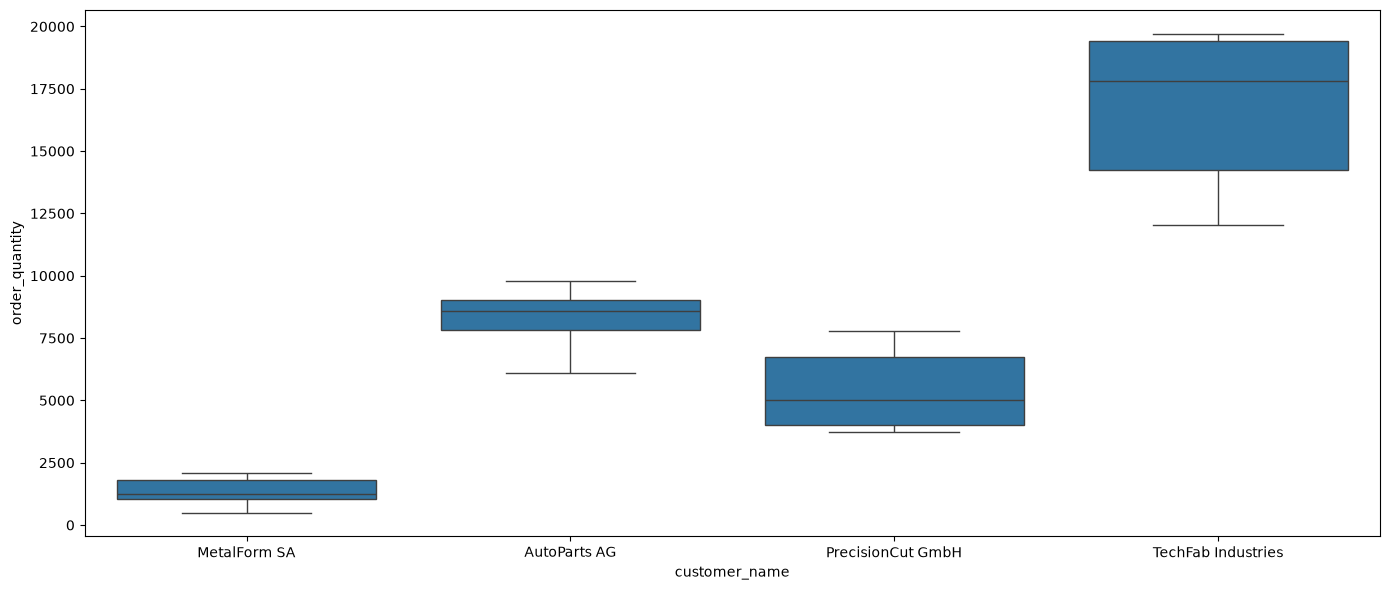

In [2]:
# Boxplot for order quantities by customer
fig, axes = plt.subplots(1, 1, figsize=(14, 6))
sns.boxplot(clean_data, x='customer_name', y='order_quantity')
plt.tight_layout()
plt.show()

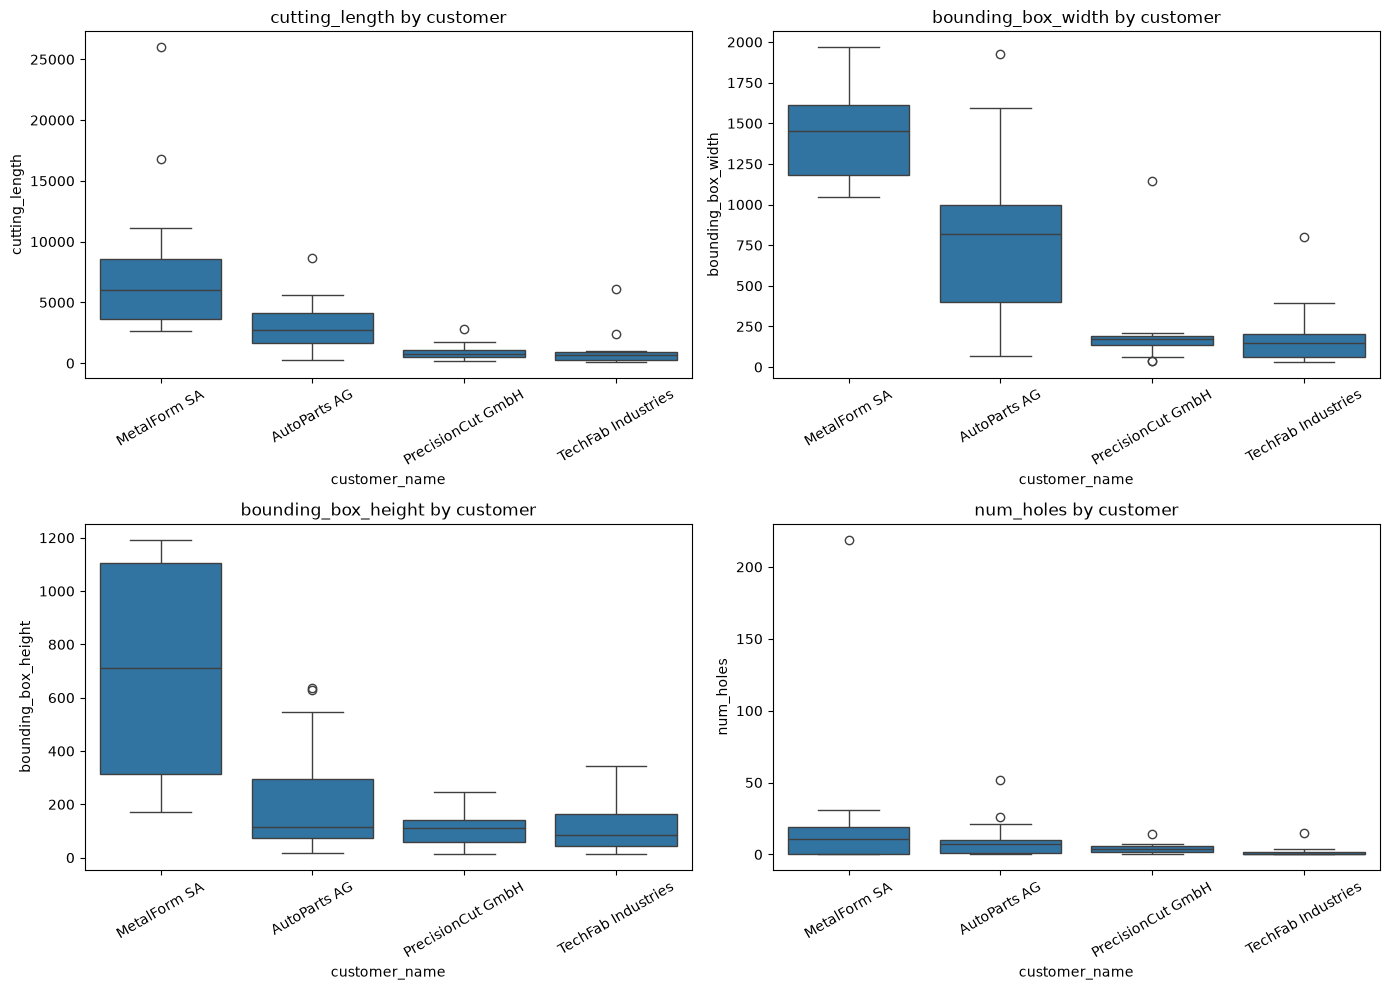

In [3]:
# boxplots for cutting length, bounding box width, bounding box height, and number of holes by customer!
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
variables = [
    'cutting_length',
    'bounding_box_width',
    'bounding_box_height',
    'num_holes'
]

for ax, col in zip(axes.flat, variables):

    sns.boxplot(
        data=clean_data,
        x='customer_name',
        y=col,
        ax=ax
    )

    ax.set_title(f'{col} by customer')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

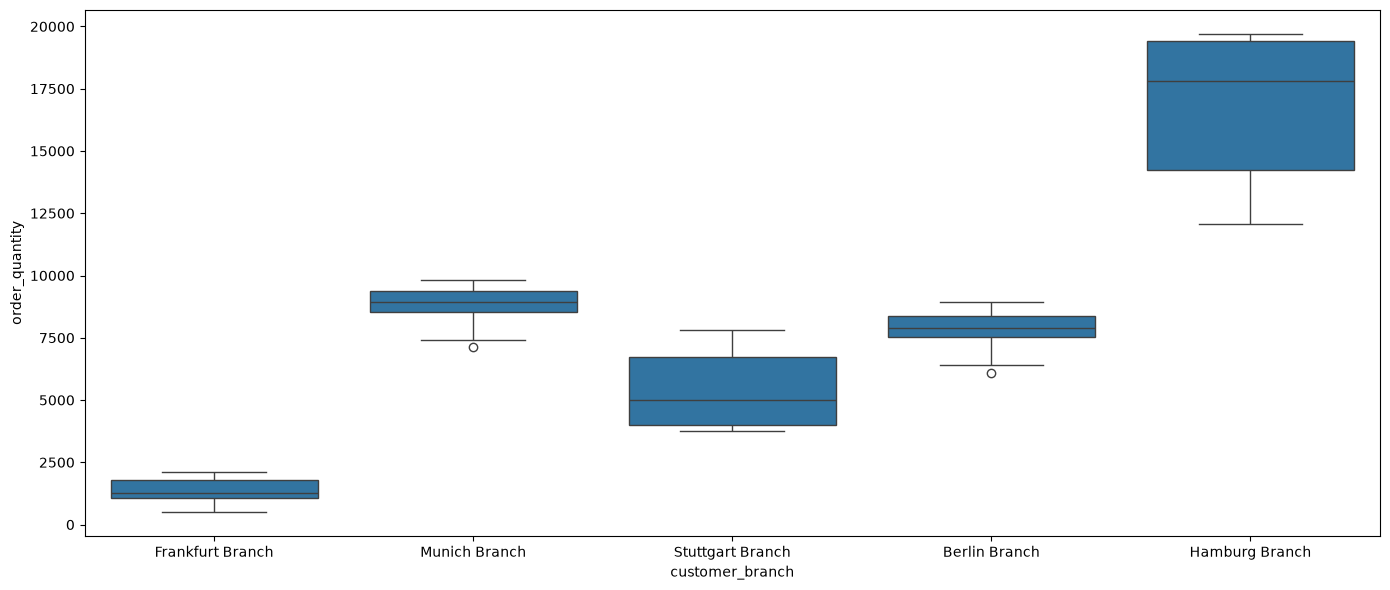

In [4]:
# boxplot for customer branch by order quantity
fig, axes = plt.subplots(1, 1, figsize=(14, 6))
sns.boxplot(clean_data, x='customer_branch', y='order_quantity')
plt.tight_layout()
plt.show()

#### Scatterplots

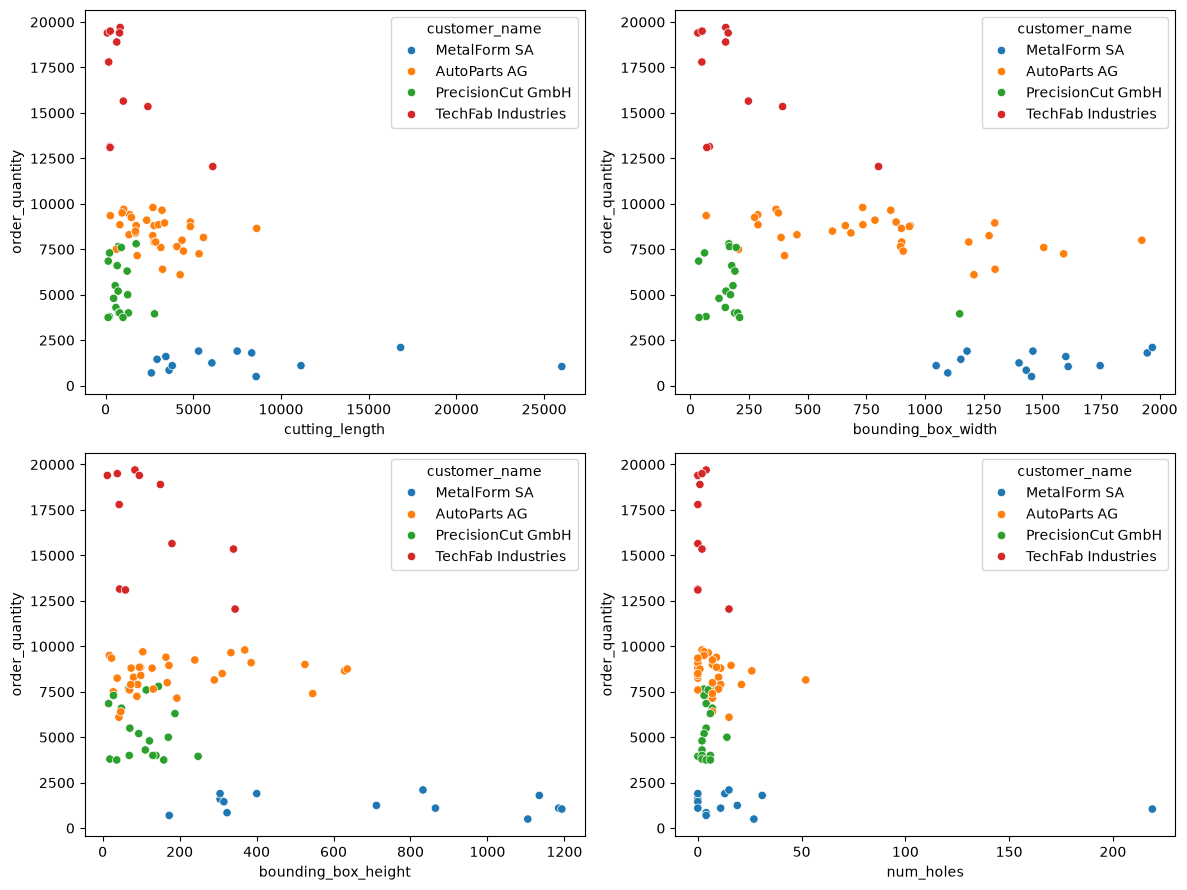

In [5]:
#scatter plots to search for conections betweens the variables
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, ['cutting_length', 'bounding_box_width', 'bounding_box_height', 'num_holes']):
    sns.scatterplot(clean_data, x=col, y='order_quantity', hue='customer_name', ax=ax)
plt.tight_layout()
plt.show()

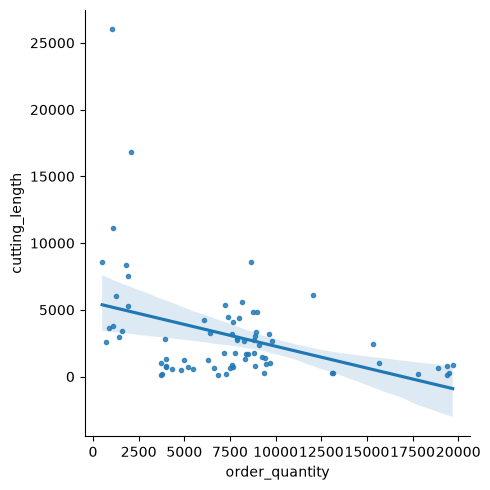

In [6]:
# additional regression line
sns.lmplot(clean_data, x='order_quantity', y='cutting_length', markers='.')
plt.show()

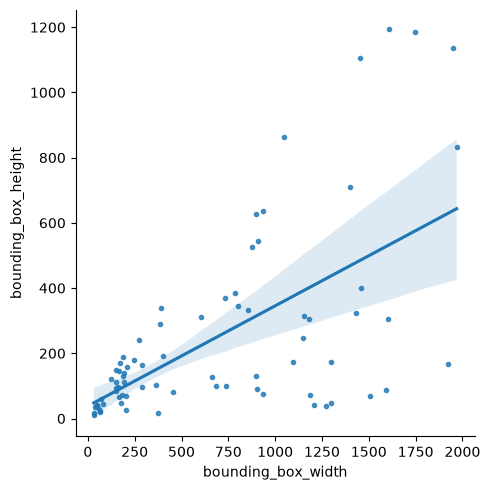

In [7]:
sns.lmplot(clean_data, x='bounding_box_width', y='bounding_box_height', markers='.')
plt.show()

#### Histograms


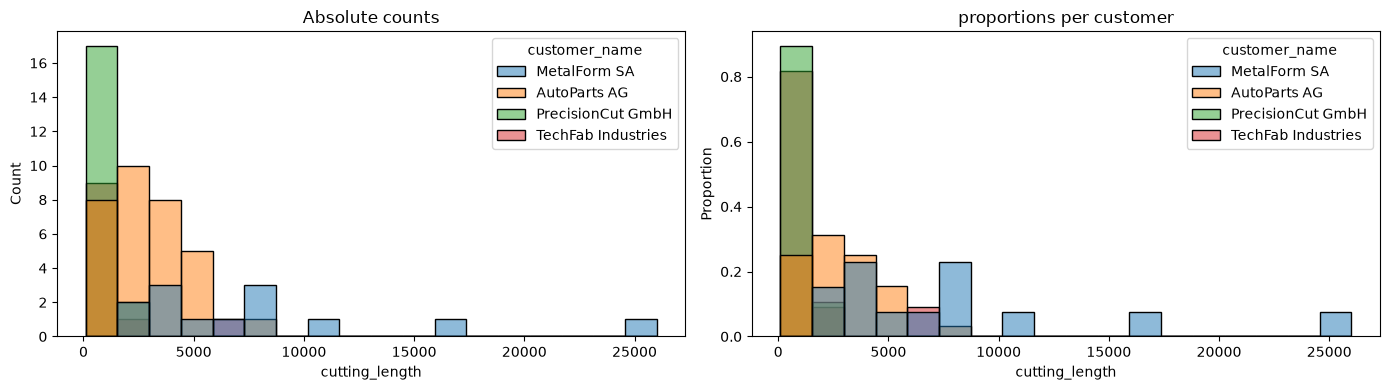

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='cutting_length', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='cutting_length', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

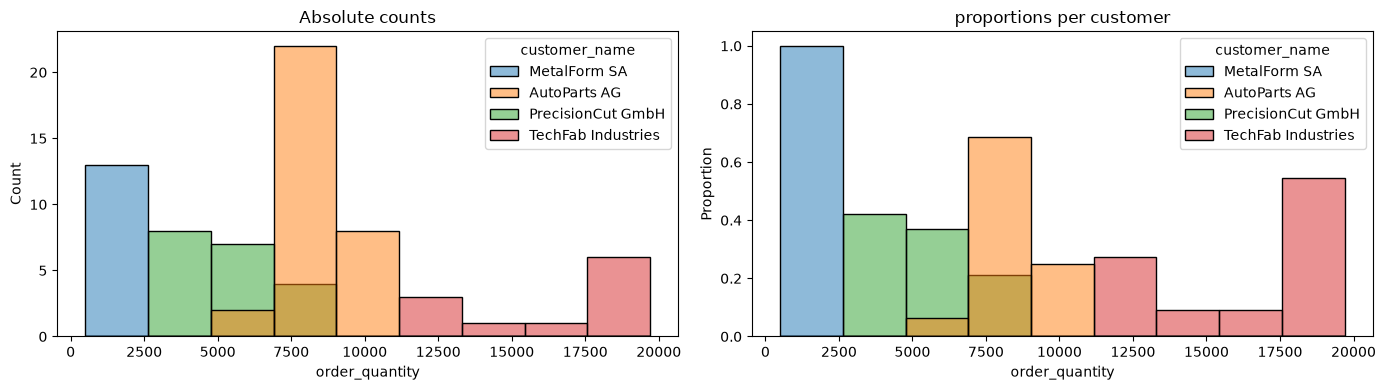

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='order_quantity', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='order_quantity', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

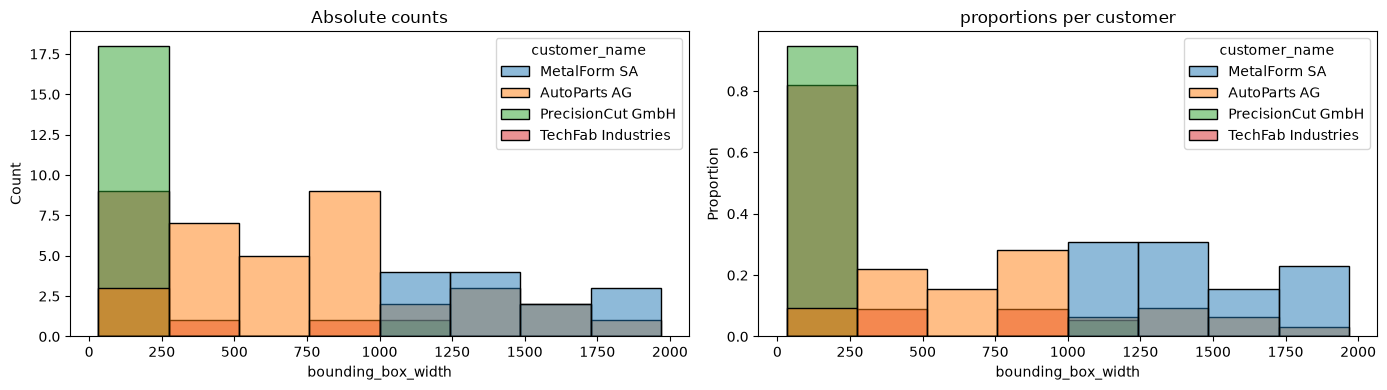

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='bounding_box_width', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='bounding_box_width', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

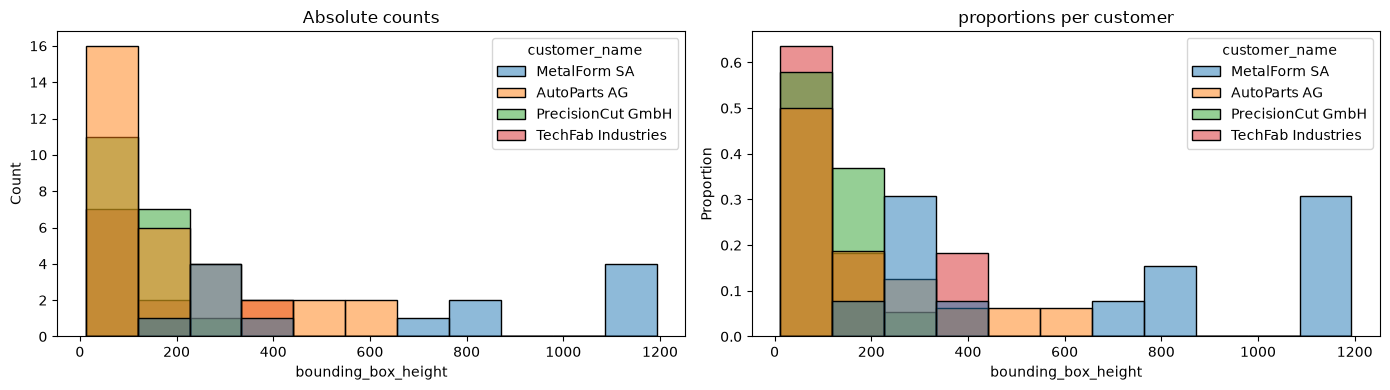

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='bounding_box_height', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='bounding_box_height', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

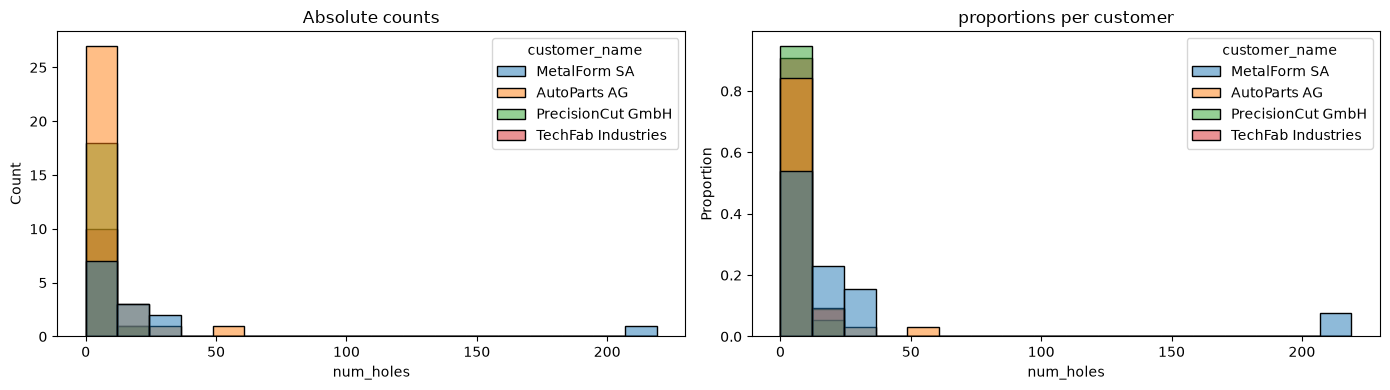

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='num_holes', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='num_holes', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

## Multivariate analysis

#### Correlation matrix

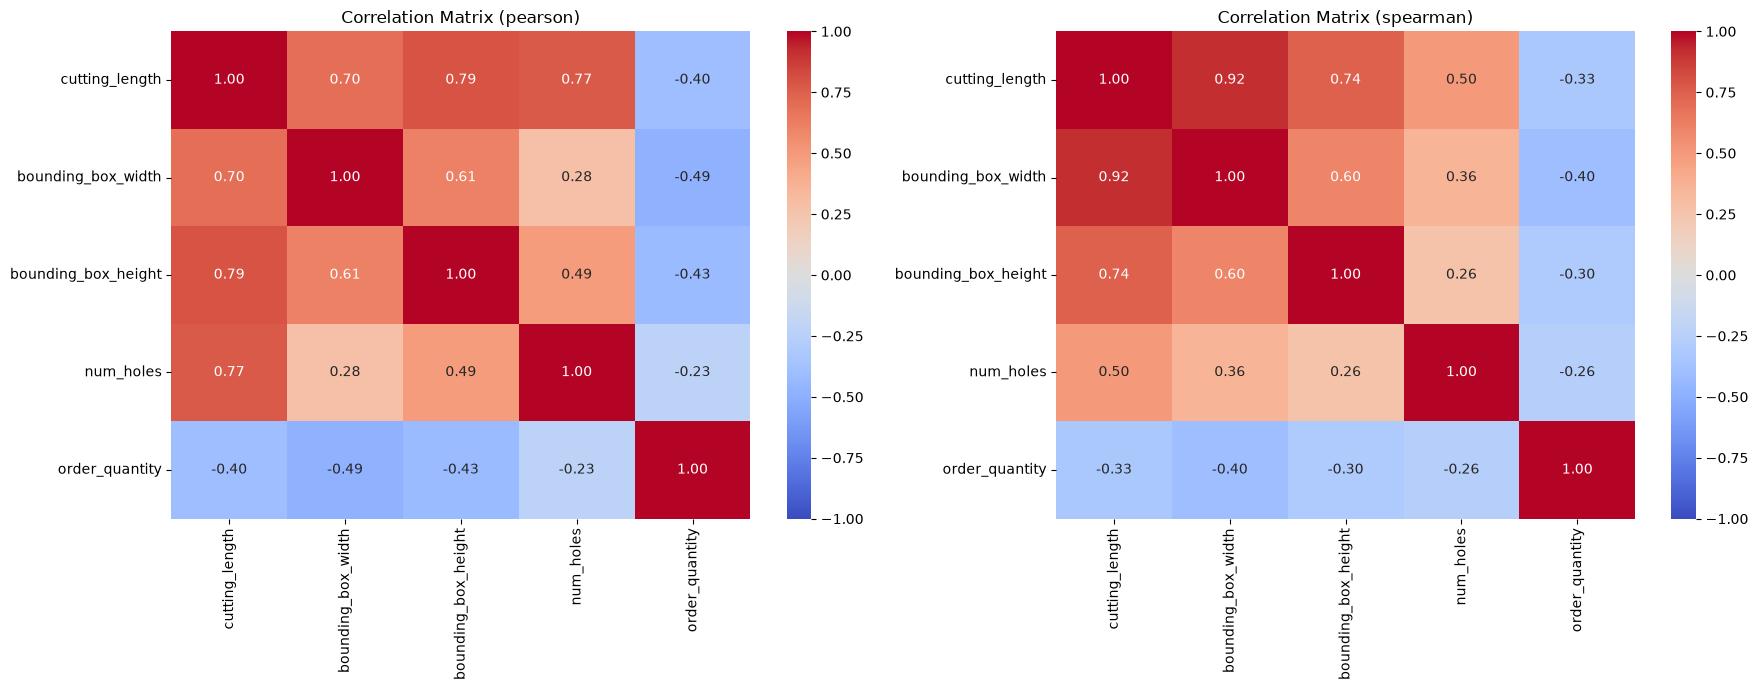

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, method in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(clean_data[['cutting_length', 'bounding_box_width', 'bounding_box_height', 'num_holes', 'order_quantity']].corr(method=method), annot=True, fmt='.2f',
                cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(f'Correlation Matrix ({method})')
plt.tight_layout()
plt.show()

In [14]:
from scipy.stats import pearsonr, spearmanr

variables = [
    'order_quantity',
    'cutting_length',
    'bounding_box_width',
    'bounding_box_height',
    'num_holes'
]

results = []

for i in range(len(variables)):
    for j in range(i + 1, len(variables)):

        x = clean_data[variables[i]]
        y = clean_data[variables[j]]

        r_p, p_p = pearsonr(x, y)
        r_s, p_s = spearmanr(x, y)

        results.append({
            'Variable 1': variables[i],
            'Variable 2': variables[j],
            'Pearson r': r_p,
            'Pearson p': p_p,
            'Spearman rho': r_s,
            'Spearman p': p_s
        })

results_df = pd.DataFrame(results)
print(results_df.round(4))



            Variable 1           Variable 2  Pearson r  Pearson p  \
0       order_quantity       cutting_length    -0.3990     0.0004   
1       order_quantity   bounding_box_width    -0.4891     0.0000   
2       order_quantity  bounding_box_height    -0.4288     0.0001   
3       order_quantity            num_holes    -0.2255     0.0517   
4       cutting_length   bounding_box_width     0.6950     0.0000   
5       cutting_length  bounding_box_height     0.7937     0.0000   
6       cutting_length            num_holes     0.7723     0.0000   
7   bounding_box_width  bounding_box_height     0.6109     0.0000   
8   bounding_box_width            num_holes     0.2774     0.0160   
9  bounding_box_height            num_holes     0.4895     0.0000   

   Spearman rho  Spearman p  
0       -0.3250      0.0044  
1       -0.3992      0.0004  
2       -0.2970      0.0097  
3       -0.2633      0.0225  
4        0.9150      0.0000  
5        0.7434      0.0000  
6        0.4969      0.0000  


#### Pairplot

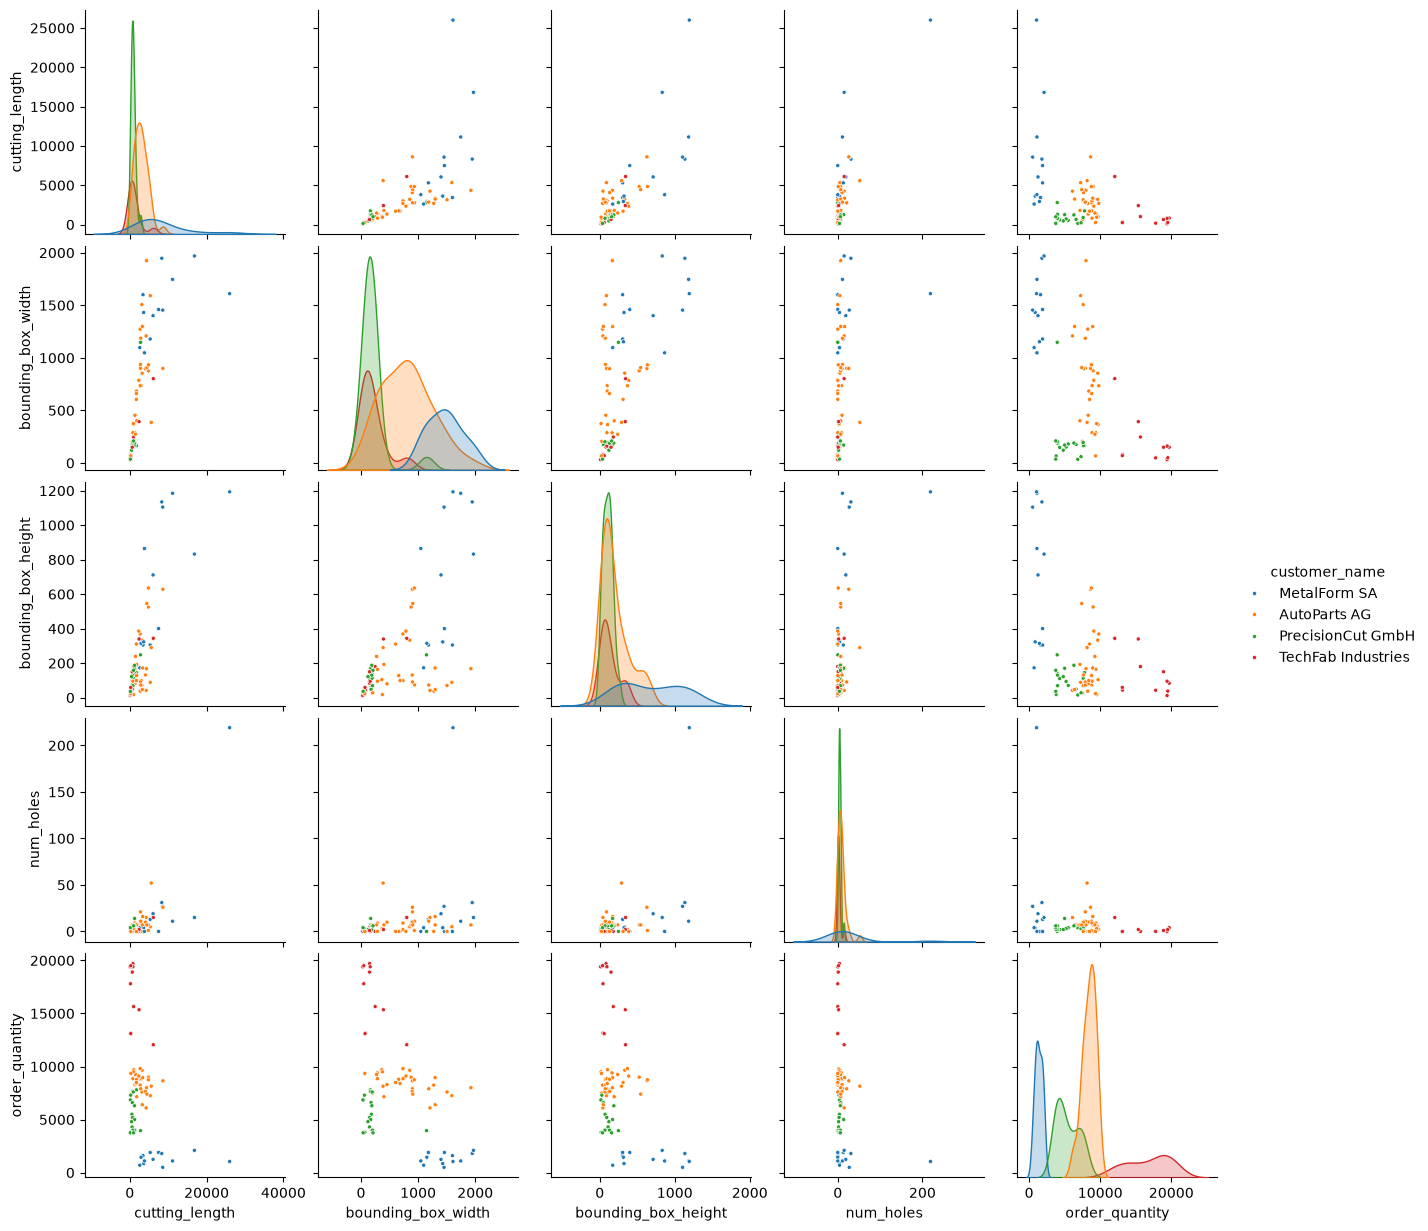

In [15]:
sns.pairplot(clean_data, vars=['cutting_length', 'bounding_box_width', 'bounding_box_height', 'num_holes', 'order_quantity'], hue='customer_name', diag_kind='kde', markers='.')
plt.show()

# Outlier: Geo(54)

# Customer analysis

### Order size per customer

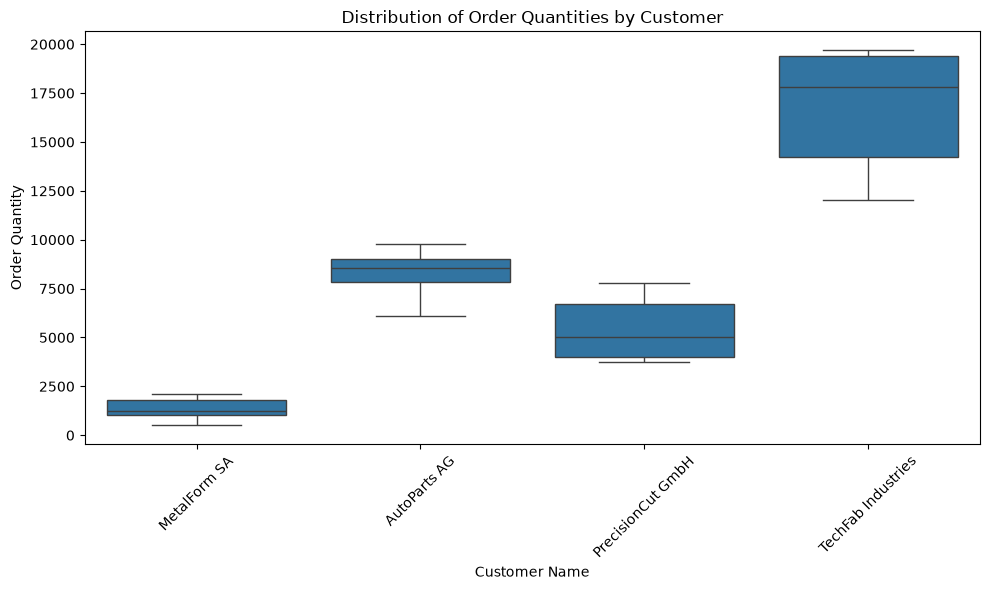

In [16]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=clean_data, x='customer_name', y='order_quantity')
plt.xticks(rotation=45)
plt.xlabel('Customer Name')
plt.ylabel('Order Quantity')
plt.title('Distribution of Order Quantities by Customer')
plt.tight_layout()
plt.show()

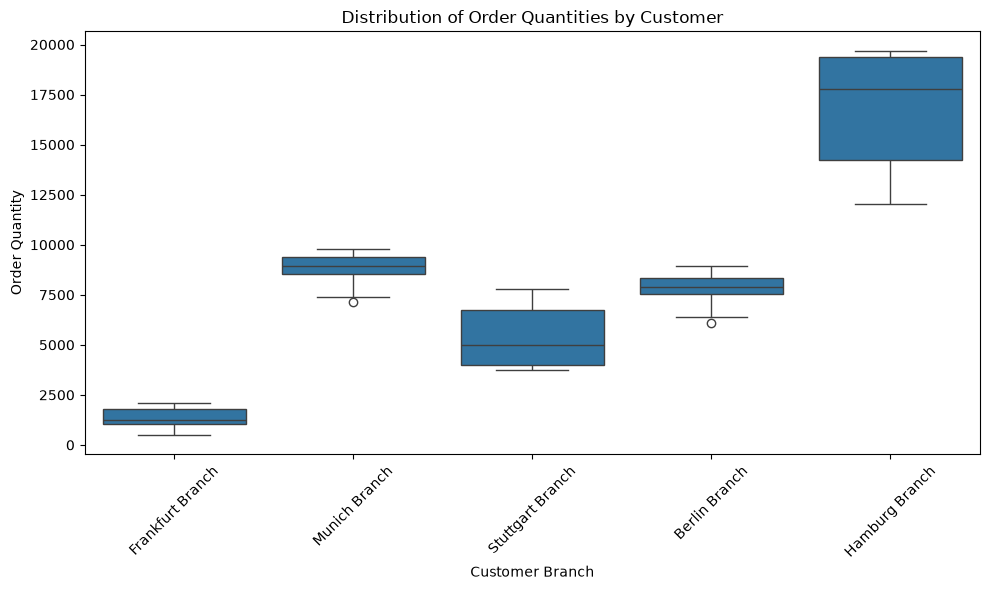

In [17]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=clean_data, x='customer_branch', y='order_quantity')
plt.xticks(rotation=45)
plt.xlabel('Customer Branch')
plt.ylabel('Order Quantity')
plt.title('Distribution of Order Quantities by Customer')
plt.tight_layout()
plt.show()

### technical features of the customers orders

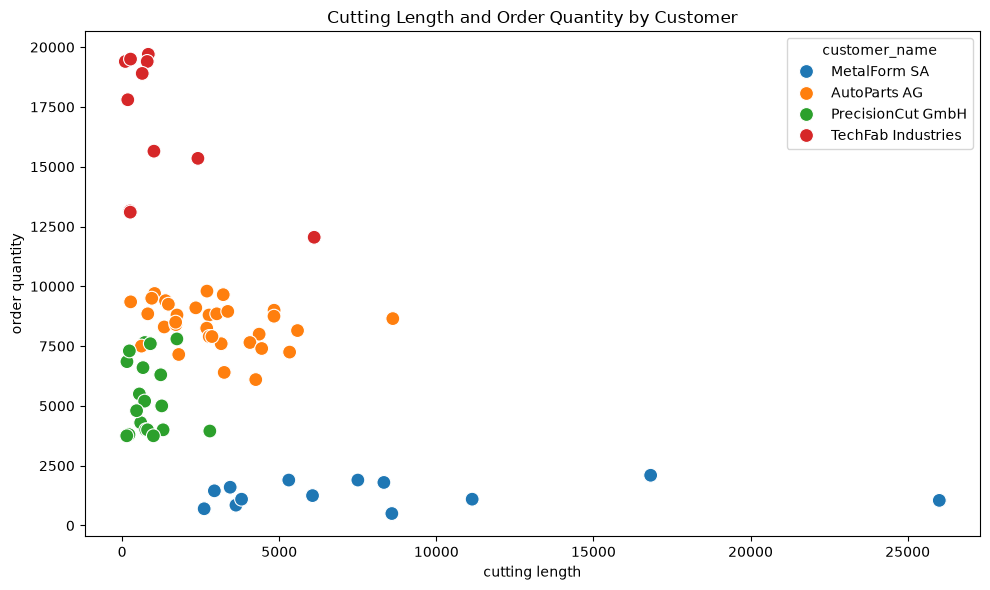

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clean_data,
    x='cutting_length',
    y='order_quantity',
    hue='customer_name',
    s=100
)

plt.title('Cutting Length and Order Quantity by Customer')
plt.xlabel('cutting length')
plt.ylabel('order quantity')
plt.tight_layout()
plt.show()

### customer profiles

In [19]:
plt.figure(figsize=(8, 4))

sns.heatmap(
    customer_profile_scaled,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    annot_kws={'size': 9},
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title('Comparison of Customer Profiles', fontsize=12)
plt.xlabel('Technical Features', fontsize=10)
plt.ylabel('Customers', fontsize=10)

plt.xticks(rotation=30, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

NameError: name 'customer_profile_scaled' is not defined

<Figure size 800x400 with 0 Axes>

##### -> Z-transformation

### Differences between the customers

In [ ]:
from scipy.stats import kruskal

groups = [
    group['bounding_box_width'].values
    for name, group in clean_data.groupby('customer_name')
]

statistic, p_value = kruskal(*groups)

print("Kruskal-Wallis-Test")
print("test statistic:", statistic)
print("p-value:", p_value)

Kruskal-Wallis-Test
test statistic: 49.95661267748875
p-value: 8.160978203257067e-11


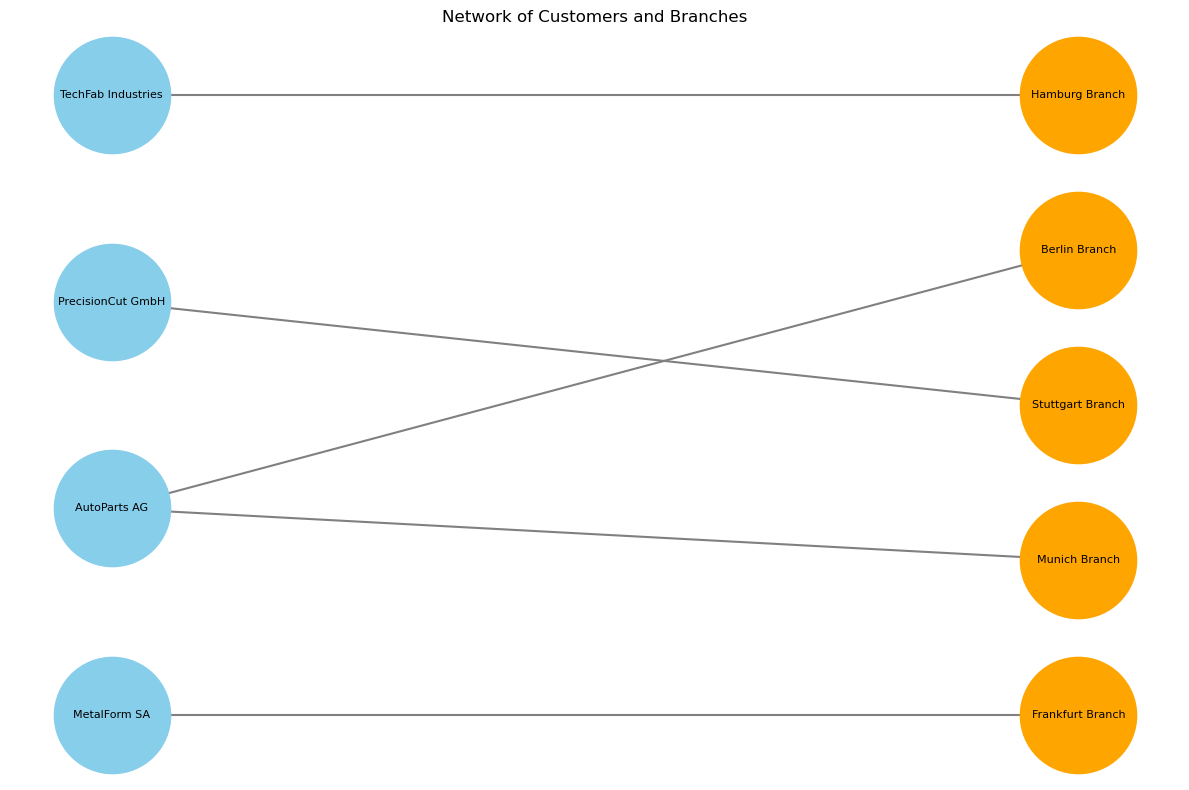

In [ ]:
# initialise Network
G = nx.Graph()

# Add Customers and Branches
for _, row in clean_data.iterrows():

    customer = row['customer_name']
    branch = row['customer_branch']

    G.add_node(customer, type='customer')
    G.add_node(branch, type='branch')

    G.add_edge(customer, branch)

# Split nodes by type
customers = [
    n for n, d in G.nodes(data=True)
    if d['type'] == 'customer'
]

branches = [
    n for n, d in G.nodes(data=True)
    if d['type'] == 'branch'
]

# lock in positions
pos = nx.bipartite_layout(G, customers)

# draw the graph
plt.figure(figsize=(12, 8))

nx.draw_networkx_edges(
    G, pos,
    edge_color='gray',
    width=1.5
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=customers,
    node_color='skyblue',
    node_size=7000,
    label='Kunden'
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=branches,
    node_color='orange',
    node_size=7000,
    label='Branches'
)

nx.draw_networkx_labels(
    G, pos,
    font_size=8
)

plt.title('Network of Customers and Branches')
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
ezdxf('Geo(2)')

NameError: name 'ezdxf' is not defined